# Human safety scoring (TrueSkill-style)

Rank the SPECS images by human-perceived safety using pairwise human choices with
`openskill` (Thurstone-Mosteller, the model
family behind TrueSkill). Ties (`equal`) are treated as draws.

This first section builds the human image ranking and selects the safest / least safe
images that have strong human agreement. Model-results and image-resolution analyses
come in later sections.


In [1]:
import sys
from collections import defaultdict

import numpy as np
import pandas as pd
from openskill.models import ThurstoneMostellerFull

sys.path.insert(0, "..")

from src.config import PROJECT_ROOT

DATA_FILE = PROJECT_ROOT / "data" / "specs_data_safe.csv"

# Model results CSV (used in later model sections; leave empty for now)
CSV_NAME = "mllm_results_Qwen3-VL-30B-A3B-AWQ_persona_normal_answer_last_image_size_default_2026-10-27_02-00.csv"

# Ranking / agreement settings
RATING_EPOCHS = 20
RANDOM_SEED = 0
N_EXTREMES = 20
MIN_APPEARANCES = 5


def show(df):
    try:
        display(df)
    except NameError:
        print(df.to_string(index=False))

print(f"{DATA_FILE = }")


d:\UTFPR\Mestrado\MLLM-Street-Perception\notebooks\..
DATA_FILE = WindowsPath('d:/UTFPR/Mestrado/MLLM-Street-Perception/notebooks/../data/specs_data_safe.csv')


In [2]:
data = pd.read_csv(DATA_FILE)

required = ["left_image_id", "right_image_id", "left_image_name", "right_image_name", "Score"]
missing = [c for c in required if c not in data.columns]
assert not missing, f"Missing columns: {missing}"

valid_scores = {"left", "right", "equal"}
bad_scores = set(data["Score"].astype(str).str.strip().str.lower().unique()) - valid_scores
assert not bad_scores, f"Unexpected Score values: {bad_scores}"

print(data.shape)
print(data["Score"].value_counts())


(5000, 52)
Score
left     1962
right    1910
equal    1128
Name: count, dtype: int64


In [3]:
names, cities, paths = {}, {}, {}
stats = defaultdict(lambda: {"wins": 0, "losses": 0, "draws": 0})

for _, row in data.iterrows():
    left_id = int(row["left_image_id"])
    right_id = int(row["right_image_id"])
    score = str(row["Score"]).strip().lower()

    names.setdefault(left_id, row["left_image_name"])
    names.setdefault(right_id, row["right_image_name"])
    cities.setdefault(left_id, row.get("left_city"))
    cities.setdefault(right_id, row.get("right_city"))
    paths.setdefault(left_id, row.get("left_path"))
    paths.setdefault(right_id, row.get("right_path"))

    if score == "left":
        stats[left_id]["wins"] += 1
        stats[right_id]["losses"] += 1
    elif score == "right":
        stats[left_id]["losses"] += 1
        stats[right_id]["wins"] += 1
    else:  # equal
        stats[left_id]["draws"] += 1
        stats[right_id]["draws"] += 1

print(f"images: {len(names)}")


images: 400


In [4]:
def wilson_interval(successes, n, z=1.96):
    if n == 0:
        return 0.0, 1.0
    p = successes / n
    denom = 1.0 + z * z / n
    center = (p + z * z / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return max(0.0, center - half), min(1.0, center + half)


image_ids = sorted(names)
matches = [
    (int(a), int(b), str(c).strip().lower())
    for a, b, c in data[["left_image_id", "right_image_id", "Score"]].itertuples(
        index=False, name=None
    )
]

mu_samples = defaultdict(list)
sigma_samples = defaultdict(list)
rng = np.random.default_rng(RANDOM_SEED)

# TrueSkill is order-dependent; average final ratings over shuffled epochs.
for _ in range(RATING_EPOCHS):
    model = ThurstoneMostellerFull()
    ratings = {img: model.rating() for img in image_ids}
    for i in rng.permutation(len(matches)):
        left_id, right_id, score = matches[i]
        if score == "left":
            ranks = [1, 2]
        elif score == "right":
            ranks = [2, 1]
        else:  # equal -> draw
            ranks = [1, 1]
        [[left_rating], [right_rating]] = model.rate(
            [[ratings[left_id]], [ratings[right_id]]],
            ranks=ranks,
            tau=0.0,
        )
        ratings[left_id] = left_rating
        ratings[right_id] = right_rating
    for img, rating in ratings.items():
        mu_samples[img].append(float(rating.mu))
        sigma_samples[img].append(float(rating.sigma))

records = []
for img in image_ids:
    s = stats[img]
    n = s["wins"] + s["losses"] + s["draws"]
    decisive = s["wins"] + s["losses"]
    decisive_rate = s["wins"] / decisive if decisive else 0.0
    ci_low, ci_high = wilson_interval(s["wins"], decisive)
    mu = float(np.mean(mu_samples[img]))
    sigma = float(np.mean(sigma_samples[img]))
    records.append({
        "image_id": img,
        "image_name": names[img],
        "city": cities[img],
        "path": paths[img],
        "mu": mu,
        "sigma": sigma,
        "mu_std": float(np.std(mu_samples[img])),
        "conservative": mu - 3 * sigma,
        "appearances": n,
        "decisive": decisive,
        "wins": s["wins"],
        "losses": s["losses"],
        "draws": s["draws"],
        "win_rate": s["wins"] / n if n else 0.0,
        "decisive_rate": decisive_rate,
        "decisive_ci_low": ci_low,
        "decisive_ci_high": ci_high,
        "draw_rate": s["draws"] / n if n else 0.0,
    })

ratings_df = (
    pd.DataFrame(records)
    .sort_values(["mu", "sigma"], ascending=[False, True])
    .reset_index(drop=True)
)
ratings_df["rank"] = np.arange(1, len(ratings_df) + 1)
show(ratings_df.head(10))


,image_id,image_name,city,path,mu,sigma,mu_std,conservative,appearances,decisive,wins,losses,draws,win_rate,decisive_rate,decisive_ci_low,decisive_ci_high,draw_rate,rank
0,389,Image_389,Amsterdam,data/SPECS/svi/Amsterdam/d8044123-3bdc-48b4-8f...,32.423546,3.679073,1.300342,21.386328,12,9,9,0,3,0.750000,1.000000,0.700847,1.000000,0.250000,1
1,340,Image_340,Amsterdam,data/SPECS/svi/Amsterdam/b71f04fc-4d5c-46d7-90...,31.878151,2.558747,1.167729,24.201911,33,26,23,3,7,0.696970,0.884615,0.710237,0.959968,0.212121,2
2,166,Image_166,Singapore,data/SPECS/svi/Singapore/85d8e67c-209d-4510-83...,31.866282,2.715227,1.194134,23.720603,31,26,24,2,5,0.774194,0.923077,0.758581,0.978645,0.161290,3
3,328,Image_328,Amsterdam,data/SPECS/svi/Amsterdam/f52af108-1b6b-4de6-a9...,31.563811,3.000318,1.178667,22.562857,23,20,18,2,3,0.782609,0.900000,0.698962,0.972134,0.130435,4
4,383,Image_383,Amsterdam,data/SPECS/svi/Amsterdam/967ce34c-4277-4cd0-84...,31.189606,2.784112,1.199514,22.837269,30,26,23,3,4,0.766667,0.884615,0.710237,0.959968,0.133333,5
5,354,Image_354,Amsterdam,data/SPECS/svi/Amsterdam/03953c0b-6b22-4a31-93...,30.765269,3.352996,0.969546,20.706282,16,14,12,2,2,0.750000,0.857143,0.600581,0.959907,0.125000,6
6,283,Image_283,San Francisco,data/SPECS/svi/San Francisco/3f514c22-e89b-477...,30.666489,2.874925,1.210079,22.041713,24,21,18,3,3,0.750000,0.857143,0.653635,0.950191,0.125000,7
7,115,Image_115,Abuja,data/SPECS/svi/Abuja/caf0a475-6738-4041-b469-b...,30.600270,3.010524,1.264318,21.568699,23,22,18,4,1,0.782609,0.818182,0.614830,0.926932,0.043478,8
8,365,Image_365,Amsterdam,data/SPECS/svi/Amsterdam/17d9caca-68ae-452a-8d...,30.577156,2.775064,1.120606,22.251965,25,19,17,2,6,0.680000,0.894737,0.686054,0.970642,0.240000,9
9,357,Image_357,Amsterdam,data/SPECS/svi/Amsterdam/72dfc78e-3216-4dc0-a8...,30.181940,2.575796,0.980473,22.454552,36,34,26,8,2,0.722222,0.764706,0.600035,0.875632,0.055556,10


In [5]:
agree = ratings_df[ratings_df["appearances"] >= MIN_APPEARANCES]

safe = (
    agree[agree["decisive_ci_low"] > 0.5]
    .sort_values("mu", ascending=False)
    .head(N_EXTREMES)
)
unsafe = (
    agree[agree["decisive_ci_high"] < 0.5]
    .sort_values("mu", ascending=True)
    .head(N_EXTREMES)
)

print(f"Images significantly chosen as safer: {len(agree[agree['decisive_ci_low'] > 0.5])}")
print(f"Images significantly chosen as less safe: {len(agree[agree['decisive_ci_high'] < 0.5])}")

cols = [
    "rank", "image_name", "city", "mu", "sigma", "conservative",
    "appearances", "decisive", "wins", "losses", "draws",
    "win_rate", "decisive_rate", "decisive_ci_low", "decisive_ci_high",
]

print("\nSAFEST (major human agreement)")
show(safe[cols].reset_index(drop=True))

print("\nLEAST SAFE (major human agreement)")
show(unsafe[cols].reset_index(drop=True))


Images significantly chosen as safer: 46
Images significantly chosen as less safe: 39

SAFEST (major human agreement)


,rank,image_name,city,mu,sigma,conservative,appearances,decisive,wins,losses,draws,win_rate,decisive_rate,decisive_ci_low,decisive_ci_high
0,1,Image_389,Amsterdam,32.423546,3.679073,21.386328,12,9,9,0,3,0.750000,1.000000,0.700847,1.000000
1,2,Image_340,Amsterdam,31.878151,2.558747,24.201911,33,26,23,3,7,0.696970,0.884615,0.710237,0.959968
2,3,Image_166,Singapore,31.866282,2.715227,23.720603,31,26,24,2,5,0.774194,0.923077,0.758581,0.978645
3,4,Image_328,Amsterdam,31.563811,3.000318,22.562857,23,20,18,2,3,0.782609,0.900000,0.698962,0.972134
4,5,Image_383,Amsterdam,31.189606,2.784112,22.837269,30,26,23,3,4,0.766667,0.884615,0.710237,0.959968
5,6,Image_354,Amsterdam,30.765269,3.352996,20.706282,16,14,12,2,2,0.750000,0.857143,0.600581,0.959907
6,7,Image_283,San Francisco,30.666489,2.874925,22.041713,24,21,18,3,3,0.750000,0.857143,0.653635,0.950191
7,8,Image_115,Abuja,30.600270,3.010524,21.568699,23,22,18,4,1,0.782609,0.818182,0.614830,0.926932
8,9,Image_365,Amsterdam,30.577156,2.775064,22.251965,25,19,17,2,6,0.680000,0.894737,0.686054,0.970642
9,10,Image_357,Amsterdam,30.181940,2.575796,22.454552,36,34,26,8,2,0.722222,0.764706,0.600035,0.875632



LEAST SAFE (major human agreement)


,rank,image_name,city,mu,sigma,conservative,appearances,decisive,wins,losses,draws,win_rate,decisive_rate,decisive_ci_low,decisive_ci_high
0,400,Image_172,Singapore,15.583046,3.375942,5.455221,24,21,0,21,3,0.000000,0.000000,0.000000,0.154644
1,399,Image_20,Santiago,15.901127,2.797658,7.508151,35,33,3,30,2,0.085714,0.090909,0.031403,0.235729
2,398,Image_27,Santiago,17.253405,3.487013,6.792366,14,10,0,10,4,0.000000,0.000000,0.000000,0.277540
3,397,Image_218,Singapore,17.761963,2.740086,9.541707,34,32,5,27,2,0.147059,0.156250,0.068643,0.317545
4,396,Image_18,Santiago,18.147182,3.028854,9.060620,25,24,4,20,1,0.160000,0.166667,0.066786,0.358535
5,395,Image_54,Santiago,18.185151,3.664063,7.192962,15,14,2,12,1,0.133333,0.142857,0.040093,0.399419
6,394,Image_188,Singapore,18.468930,3.127827,9.085447,21,18,2,16,3,0.095238,0.111111,0.031019,0.328002
7,393,Image_22,Santiago,19.011150,2.935197,10.205559,23,19,3,16,4,0.130435,0.157895,0.055204,0.375659
8,392,Image_149,Abuja,19.113887,2.979662,10.174902,23,21,5,16,2,0.217391,0.238095,0.106279,0.450916
9,391,Image_329,Amsterdam,19.146405,3.113047,9.807263,19,16,3,13,3,0.157895,0.187500,0.065915,0.430094


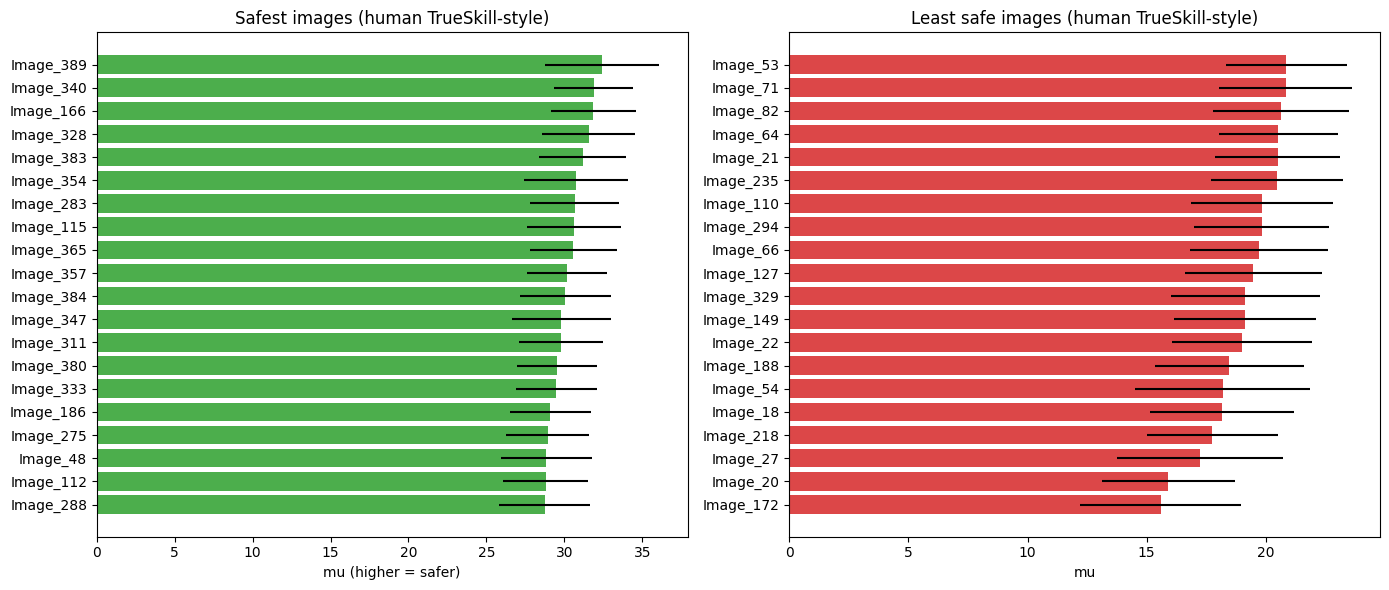

In [7]:
import matplotlib.pyplot as plt

top = safe.head(20).iloc[::-1]
bottom = unsafe.head(20)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top["image_name"], top["mu"], xerr=top["sigma"], color="tab:green", alpha=0.85)
axes[0].set_title("Safest images (human TrueSkill-style)")
axes[0].set_xlabel("mu (higher = safer)")

axes[1].barh(bottom["image_name"], bottom["mu"], xerr=bottom["sigma"], color="tab:red", alpha=0.85)
axes[1].set_title("Least safe images (human TrueSkill-style)")
axes[1].set_xlabel("mu")

plt.tight_layout()
plt.show()


## Next sections

- Load a model results CSV (`CSV_NAME`) and merge on `comparison_id`.
- Fit the same rating model to the model's choices and compare human vs model rankings
  (Spearman/Kendall, top-k overlap, largest rank shifts).
- Evaluate model accuracy on the safest / least safe / high-agreement pairs.
- Image-resolution analysis: per-image size, model/human win rates, and a within-pair
  resolution-bias test.
